In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from zipfile import ZipFile
from sklearn.model_selection import train_test_split


In [14]:
with ZipFile(r"C:\Users\ADMIN\Downloads\MNIST-20221031T095906Z-001.zip") as z:
    df=pd.read_csv(z.open("MNIST/mnist_784_csv.csv"),nrows=12000)
    df.shape
    df.head()


In [18]:
X = df.drop("class",axis=1).to_numpy(dtype=np.float32)/255
Y = df["class"].to_numpy()

print(X.shape)
print(Y.shape)


(12000, 784)
(12000,)


In [19]:
X_train,X_test,Y_train,Y_test = train_test_split(X,Y,test_size=0.2,random_state=42)

In [20]:
model = keras.Sequential([
    keras.Input(shape=(784,)),
    keras.layers.Dense(128,activation="relu"),
    keras.layers.Dense(32,activation="relu",activity_regularizer=regularizers.l1(0.00001)),
    keras.layers.Dense(256,activation="relu"),
    keras.layers.Dense(784,activation="sigmoid")

])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │         8,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 784)            │       201,488 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 314,544 (1.20 MB)

 Trainable params: 314,544 (1.20 MB)

 Non-trainable params: 0 (0.00 B)

In [21]:
model.compile(
    optimizer="adam",
    loss="mse"
)

In [22]:
history = model.fit(
    X_train,
    X_train,
    epochs=30,
    batch_size=128,
    validation_split=0.2
)

Epoch 1/30
60/60 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - loss: 0.0951 - val_loss: 0.0595
Epoch 2/30
60/60 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0505 - val_loss: 0.0433
Epoch 3/30
60/60 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0386 - val_loss: 0.0349
Epoch 4/30
60/60 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0319 - val_loss: 0.0298
Epoch 5/30
60/60 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0275 - val_loss: 0.0262
Epoch 6/30
60/60 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0244 - val_loss: 0.0235
Epoch 7/30
60/60 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0220 - val_loss: 0.0214
Epoch 8/30
60/60 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0201 - val_loss: 0.0200
Epoch 9/30
60/60 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0186 - val_loss: 0.0186
Epoch 10/30
60/60 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0173 - val_loss: 0.0174
Epoch 11/30
60/60 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0163 - val_loss: 0.0166
Epoch 12/30
60/60 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0

In [29]:
prediction=model.predict(X_test[:10])
print("Actual digit:",Y_test[0])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
Actual digit: 3


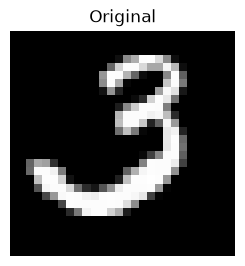

In [30]:
plt.subplot(1,2,1)
plt.imshow(X_test[0].reshape(28,28),cmap='gray')
plt.axis('off')
plt.title("Original")
plt.show()

Text(0.5, 1.0, 'Reconstructed')

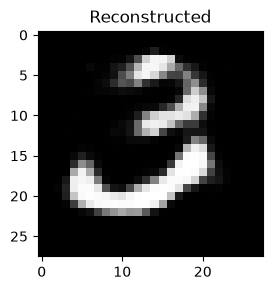

In [31]:
plt.subplot(1,2,1)
plt.imshow(prediction[0].reshape(28,28),cmap='gray')
plt.title('Reconstructed')

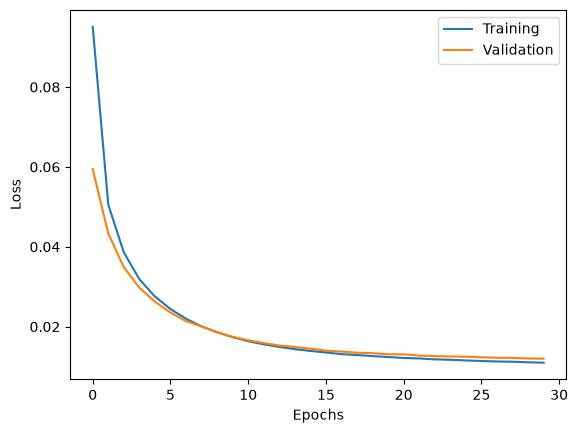

In [34]:
plt.plot(history.history['loss'],label='Training')
plt.plot(history.history['val_loss'],label='Validation')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [35]:
train_loss = history.history["loss"][-1]

val_loss = history.history["val_loss"][-1]

print("Training Loss:", round(train_loss, 4))

print("Validation Loss:", round(val_loss, 4))

Training Loss: 0.011
Validation Loss: 0.012
